Q. Implement the following machine learning algorithms from scratch using Python:
a) K-Means Clustering:Implement the K-Means clustering algorithm without using the built-in KMeans function. The implementation must include centroid initialization, distance calculation, cluster assignment, centroid updating, and iteration until convergence.

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

In [25]:
#initialization of the dataset
data = load_wine()
X = data.data
y = data.target
k = 3  # Number of clusters
max_iters = 10  # Number of iterations for K-means
centroid = None
tol=1e-4
labels = None


In [39]:
#data explorer
import pandas as pd
df = pd.DataFrame(data.data, columns=data.feature_names)
print("First 5 rows of the dataset:\n", df.head())

First 5 rows of the dataset:
    alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines 

In [40]:
#Checking the shape of the dataset
print("Original shape of the dataset:", X.shape)

Original shape of the dataset: (178, 13)


In [41]:
#checking null values
print("Checking for null values:\n", df.isnull().sum())

Checking for null values:
 alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64


In [26]:
#Checking the shape of the dataset

print("Original shape of the dataset:", X.shape)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Shape of the dataset:", X_scaled.shape)


Original shape of the dataset: (178, 13)
Shape of the dataset: (178, 13)


In [27]:
#initilize centroids
np.random.seed(42)  # For reproducibility
initial_centroid = X[np.random.choice(X_scaled.shape[0], k, replace=False)].astype(float)
print("Initial Centroids:\n", initial_centroid)
centroid = initial_centroid


Initial Centroids:
 [[1.364e+01 3.100e+00 2.560e+00 1.520e+01 1.160e+02 2.700e+00 3.030e+00
  1.700e-01 1.660e+00 5.100e+00 9.600e-01 3.360e+00 8.450e+02]
 [1.421e+01 4.040e+00 2.440e+00 1.890e+01 1.110e+02 2.850e+00 2.650e+00
  3.000e-01 1.250e+00 5.240e+00 8.700e-01 3.330e+00 1.080e+03]
 [1.293e+01 2.810e+00 2.700e+00 2.100e+01 9.600e+01 1.540e+00 5.000e-01
  5.300e-01 7.500e-01 4.600e+00 7.700e-01 2.310e+00 6.000e+02]]


In [28]:
#compute the distance between each point and the centroids
distances = np.linalg.norm(X_scaled[:, np.newaxis, :] - initial_centroid, axis=2)
labels = np.argmin(distances, axis=1)
print("Labels:\n", labels)

Labels:
 [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


In [33]:
#assign points to clusters based on the closest centroid
for _ in range(max_iters):
    # Compute distances from points to centroids
    distances = np.linalg.norm(X[:, np.newaxis, :] - centroid, axis=2)
    
    # Assign labels based on closest centroid
    labels = np.argmin(distances, axis=1)
    
    # Update centroids
    new_centroid = np.zeros((k, X.shape[1]))
    for i in range(k):
      cluster_points = X[labels == i]
      if len(cluster_points) > 0:
        new_centroid[i] = cluster_points.mean(axis=0)
      else:
        # Re-initialize to a random point if cluster becomes empty
        new_centroid[i] = X[np.random.choice(X.shape[0])]

    # Convergence Check: evaluated BEFORE updating centroid variable
    shift = np.linalg.norm(new_centroid - centroid)
    if shift < tol:
      break

    centroid = new_centroid


    
    

In [34]:
#after update 

distances = np.linalg.norm(X[:, np.newaxis, :] - centroid, axis=2)
labels = np.argmin(distances, axis=1)
print("After process -Updated labels:\n", labels)

After process -Updated labels:
 [1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 0 0 1 1 0 1 1 1 1 1 1 0 0
 1 1 0 0 1 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 0 2 0 2 2 0 2 2 0 0 0 2 2 1
 0 2 2 2 0 2 2 0 0 2 2 2 2 2 0 0 2 2 2 2 2 0 0 2 0 2 0 2 2 2 0 2 2 2 2 0 2
 2 0 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2 2 2 0 2 2 0 0 0 0 2 2 2 0 0 2 2 0 0 2 0
 0 2 2 2 2 0 0 0 2 0 0 0 2 0 2 0 0 2 0 0 0 0 2 2 0 0 0 0 0 2]


b) Linear Discriminant Analysis (LDA): Implement LDA without using the built-in LDA function. Compute the within-class scatter matrix, between-class scatter matrix, eigenvalues/eigenvectors, and project the data onto the selected discriminant components.
For both algorithms:
Use a suitable dataset. 
Do not use the corresponding machine-learning library implementation. 
Display/visualize the final results. 
Clearly explain the major steps in your Python implementation.

Projected shape: (178, 2)


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/numpy/linalg/_linalg.py:3383: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/numpy/linalg/_linalg.py:3383: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/numpy/linalg/_linalg.py:3383: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


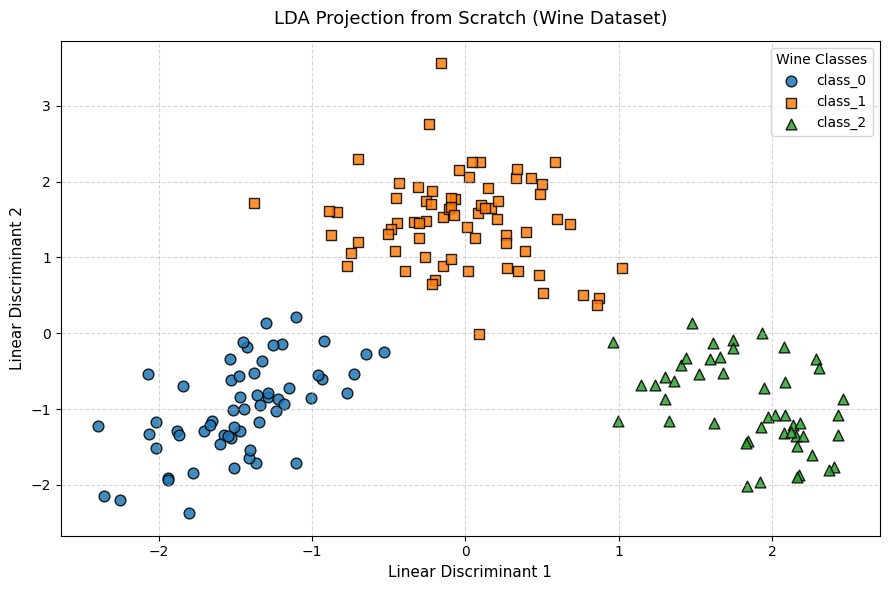

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler


class LinearDiscriminantAnalysisFromScratch:
    def __init__(self, n_components=2):
        self.n_components = n_components
        self.linear_discriminants = None

    def fit(self, X, y):
        n_features = X.shape[1]
        class_labels = np.unique(y)
        overall_mean = np.mean(X, axis=0)

        # Initialize Within-class (S_W) and Between-class (S_B) scatter matrices
        S_W = np.zeros((n_features, n_features))
        S_B = np.zeros((n_features, n_features))

        for c in class_labels:
            X_c = X[y == c]
            mean_c = np.mean(X_c, axis=0)

            # 1. Within-class scatter matrix: S_W = sum((X_c - mean_c)^T * (X_c - mean_c))
            S_W += np.dot((X_c - mean_c).T, (X_c - mean_c))

            # 2. Between-class scatter matrix: S_B = sum(N_c * (mean_c - mean_overall) * (mean_c - mean_overall)^T)
            n_c = X_c.shape[0]
            mean_diff = (mean_c - overall_mean).reshape(n_features, 1)
            S_B += n_c * np.dot(mean_diff, mean_diff.T)

        # 3. Solve the generalized eigenvalue problem: S_W^(-1) * S_B * w = lambda * w
        # np.linalg.pinv avoids singular matrix issues if S_W is non-invertible
        matrix_to_decompose = np.dot(np.linalg.pinv(S_W), S_B)
        eigenvalues, eigenvectors = np.linalg.eig(matrix_to_decompose)

        # 4. Sort eigenvectors by decreasing real eigenvalues
        eigenvectors = eigenvectors.T
        sorted_indices = np.argsort(np.abs(eigenvalues))[::-1]
        top_indices = sorted_indices[:self.n_components]

        # 5. Form the projection matrix W (features, n_components)
        self.linear_discriminants = np.real(eigenvectors[top_indices].T)
        return self

    def transform(self, X):
        # Project data onto the discriminant axes
        return np.dot(X, self.linear_discriminants)


# --- Load and Scale Data ---
wine = load_wine()
X = StandardScaler().fit_transform(wine.data)
y = wine.target
target_names = wine.target_names

# --- Fit & Transform ---
lda = LinearDiscriminantAnalysisFromScratch(n_components=2)
lda.fit(X, y)
X_projected = lda.transform(X)
print("Projected shape:", X_projected.shape)

# --- Scatter Plot ---
plt.figure(figsize=(9, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
markers = ['o', 's', '^']

for class_idx, color, marker, label in zip(np.unique(y), colors, markers, target_names):
    plt.scatter(
        X_projected[y == class_idx, 0],
        X_projected[y == class_idx, 1],
        c=color,
        marker=marker,
        edgecolors='k',
        s=60,
        alpha=0.85,
        label=label
    )

plt.title('LDA Projection from Scratch (Wine Dataset)', fontsize=13, pad=12)
plt.xlabel('Linear Discriminant 1', fontsize=11)
plt.ylabel('Linear Discriminant 2', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Wine Classes', frameon=True)
plt.tight_layout()
plt.show()